# MicroGrad: Scalar Autograd and a Tiny MLP

This notebook demonstrates the completed scalar automatic differentiation engine and neural-network API. It first checks a hand-computed derivative, then trains a small multilayer perceptron on the XOR problem using only the local `src.engine` and `src.nn` modules.

In [2]:
import math
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.engine import Value
from src.nn import MLP
random.seed(7)
print(f"Working directory: {ROOT}")

Working directory: d:\Engineering\Senior\Deep Learning\Assignments\Assignment1\assignment-1-micrograd-template


## 1. Scalar forward pass and backpropagation

For `f(a, b) = tanh(a b + a + 1)`, the engine constructs a computation graph. Calling `backward()` performs a reverse traversal of that graph and accumulates the chain-rule contributions in each leaf node.

In [3]:
a = Value(2.0, label="a")
b = Value(-3.0, label="b")
f = (a * b + a + 1).tanh()
f.backward()

expected_da = (1 - math.tanh(-3.0) ** 2) * (b.data + 1)
expected_db = (1 - math.tanh(-3.0) ** 2) * a.data

print(f"f(a, b) = {f.data:.6f}")
print(f"df/da   = {a.grad:.6f} (expected {expected_da:.6f})")
print(f"df/db   = {b.grad:.6f} (expected {expected_db:.6f})")
assert math.isclose(a.grad, expected_da)
assert math.isclose(b.grad, expected_db)
print("Analytic gradient check passed.")

f(a, b) = -0.995055
df/da   = -0.019732 (expected -0.019732)
df/db   = 0.019732 (expected 0.019732)
Analytic gradient check passed.


## 2. XOR training data

The XOR function is not linearly separable, so it provides a compact demonstration that hidden layers and nonlinear activations are useful. Targets are represented as `-1` and `+1`, matching the output range of the final `tanh` neuron.

In [4]:
data = [
    ([0.0, 0.0], -1.0),
    ([0.0, 1.0], 1.0),
    ([1.0, 0.0], 1.0),
    ([1.0, 1.0], -1.0),
]
model = MLP(2, [4, 4, 1])
print(f"Number of trainable parameters: {len(model.parameters())}")

Number of trainable parameters: 37


## 3. Manual gradient-descent training

There is no optimizer or tensor library here. Each epoch builds a scalar loss by summing squared errors, calls `backward()`, and updates every parameter with `p.data -= learning_rate * p.grad`.

In [5]:
def predict(inputs):
    return model(inputs)


def loss_value():
    losses = []
    for inputs, target in data:
        prediction = predict(inputs)
        losses.append((prediction - target) ** 2)
    return sum(losses, Value(0.0)) / len(losses)


learning_rate = 0.08
epochs = 3000
loss_history = []

for epoch in range(epochs):
    model.zero_grad()
    loss = loss_value()
    loss.backward()

    for parameter in model.parameters():
        parameter.data -= learning_rate * parameter.grad

    loss_history.append(loss.data)
    if epoch % 500 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch:4d} | loss {loss.data:.6f}")

epoch    0 | loss 1.428953
epoch  500 | loss 0.002155
epoch 1000 | loss 0.000853
epoch 1500 | loss 0.000518
epoch 2000 | loss 0.000368
epoch 2500 | loss 0.000284
epoch 2999 | loss 0.000230


In [6]:
predictions = [(inputs, target, predict(inputs).data) for inputs, target in data]
correct = sum((prediction >= 0) == (target >= 0) for _, target, prediction in predictions)
accuracy = correct / len(data)

print(f"Final accuracy: {accuracy:.0%}")
for inputs, target, prediction in predictions:
    print(f"input={inputs}, target={target:+.0f}, prediction={prediction:+.4f}")

assert accuracy == 1.0
assert loss_history[-1] < loss_history[0]
print("XOR training checks passed.")

Final accuracy: 100%
input=[0.0, 0.0], target=-1, prediction=-0.9896
input=[0.0, 1.0], target=+1, prediction=+0.9850
input=[1.0, 0.0], target=+1, prediction=+0.9845
input=[1.0, 1.0], target=-1, prediction=-0.9814
XOR training checks passed.


## 4. Visualizations

The first plot shows optimization progress. The second plot compares the learned prediction with the target for each XOR input.

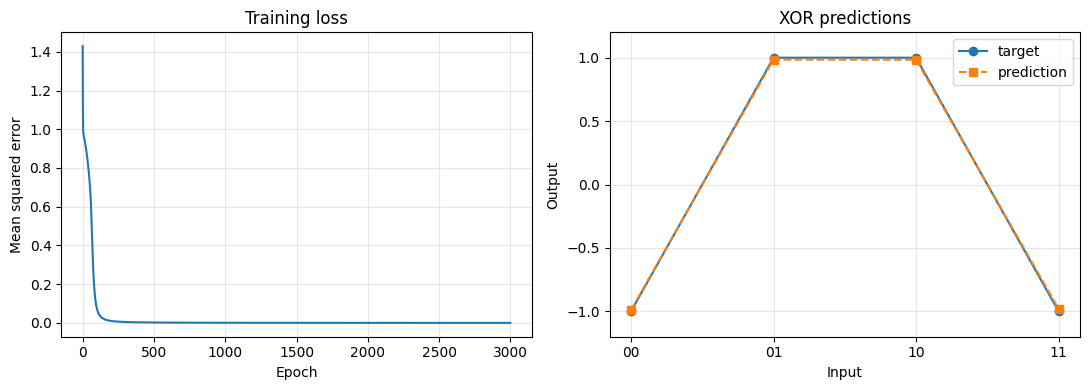

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(loss_history)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean squared error")
axes[0].grid(alpha=0.3)

labels = ["00", "01", "10", "11"]
targets = [target for _, target in data]
learned = [prediction for _, _, prediction in predictions]
positions = range(len(labels))
axes[1].plot(positions, targets, "o-", label="target")
axes[1].plot(positions, learned, "s--", label="prediction")
axes[1].set_xticks(list(positions), labels)
axes[1].set_ylim(-1.2, 1.2)
axes[1].set_title("XOR predictions")
axes[1].set_xlabel("Input")
axes[1].set_ylabel("Output")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()